In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

In [50]:
df = pd.read_csv("/content/support_tickets.csv")

In [51]:
df

,flags,utterance,category,intent,text_length
0,BM,I have problems with canceling an order,ORDER,cancel_order,7
1,BIM,how can I find information about canceling ord...,ORDER,cancel_order,8
2,B,I need help with canceling the last order,ORDER,cancel_order,8
3,BIP,could you help me cancelling the last order I ...,ORDER,cancel_order,10
4,B,problem with cancelling an order I made,ORDER,cancel_order,7
...,...,...,...,...,...
8170,BM,I need help to check if there is any updates o...,REFUND,track_refund,13
8171,BK,refund status,REFUND,track_refund,2
8172,BI,how can I check the status of the refund?,REFUND,track_refund,9
8173,B,help checking if there is anything wrong with ...,REFUND,track_refund,10


In [52]:
df.head()


,flags,utterance,category,intent,text_length
0,BM,I have problems with canceling an order,ORDER,cancel_order,7
1,BIM,how can I find information about canceling ord...,ORDER,cancel_order,8
2,B,I need help with canceling the last order,ORDER,cancel_order,8
3,BIP,could you help me cancelling the last order I ...,ORDER,cancel_order,10
4,B,problem with cancelling an order I made,ORDER,cancel_order,7


In [53]:
df.columns

Index(['flags', 'utterance', 'category', 'intent', 'text_length'], dtype='object')

# coverting text into lower case

In [54]:
df['Lower_text'] = df['utterance'].astype(str).str.lower()


# Removing the html tags

In [55]:
df["no_html"] = df["Lower_text"].apply(
    lambda x: re.sub(r"<.*?>", "", x)
)

# Removing url


In [56]:
df["no_url"] = df["no_html"].apply(
    lambda x: re.sub(r"http\S+|www\S+", "", x)
)

# Reoving Email


In [57]:
df["no_email"] = df["no_url"].apply(
    lambda x: re.sub(r"\S+@\S+", "", x)
)

# Removing special characters

In [58]:
df["clean_text"] = df["no_email"].apply(
    lambda x: re.sub(r"[^a-zA-Z0-9\s]", "", x)
)

# Removing extra spaces

In [59]:
df["clean_text"] = df["clean_text"].apply(
    lambda x: re.sub(r"\s+", " ", x).strip()
)

# Tokenization

In [60]:
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [61]:
from nltk.tokenize import word_tokenize
word_tokenize = nltk.tokenize.word_tokenize

df["tokens"] = df["clean_text"].apply(word_tokenize)


# Stopword removal

In [62]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words("english"))
negation_words = {
    "no", "nor", "not", "never",
    "neither", "n't"
    }

custom_stopwords = stop_words - negation_words


In [63]:
df["filtered_tokens"] = df["tokens"].apply(
    lambda tokens: [
        word for word in tokens
        if word.lower() not in custom_stopwords
    ]
)


# Lemmatizer

In [64]:
nltk.download("averaged_perceptron_tagger_eng")

from nltk import pos_tag
from nltk.corpus import wordnet

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


In [65]:
def get_wordnet_pos(tag):

    if tag.startswith("J"):
        return wordnet.ADJ

    elif tag.startswith("V"):
        return wordnet.VERB

    elif tag.startswith("N"):
        return wordnet.NOUN

    elif tag.startswith("R"):
        return wordnet.ADV

    else:
        return wordnet.NOUN

In [66]:
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
def lemmatize_words(tokens):

    tagged_words = pos_tag(tokens)

    lemmatized = []

    for word, tag in tagged_words:

        pos = get_wordnet_pos(tag)

        lemma = lemmatizer.lemmatize(
            word,
            pos=pos
        )

        lemmatized.append(lemma)

    return lemmatized

In [67]:
df["lemmatized_tokens"] = df["filtered_tokens"].apply(
    lemmatize_words
)

df["lemmatized_text"] = df["lemmatized_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

In [68]:
def preprocess_text(text):

    # 1. Convert to string
    text = str(text)

    # 2. Lowercase
    text = text.lower()

    # 3. Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # 4. Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # 5. Remove email addresses
    text = re.sub(r"\S+@\S+", "", text)

    # 6. Remove special characters
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # 7. Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # 8. Tokenization
    tokens = word_tokenize(text)

    # 9. Stopword removal (preserve negation)
    stop_words = set(stopwords.words("english"))
    negation_words = {
    "no", "nor", "not", "never",
    "neither", "n't"
    }

    custom_stopwords = stop_words - negation_words
    tokens = [
        word for word in tokens
        if word not in custom_stopwords
    ]



    # 10. POS-based lemmatization
    tokens = lemmatize_words(tokens)

    # 11. Convert tokens back to text
    return " ".join(tokens)

In [72]:
df["processed_text"] = df["utterance"].apply(
    preprocess_text
)


In [73]:
original_words = " ".join(
    df["utterance"].astype(str)
).lower().split()

print("Original vocabulary size:",
      len(set(original_words)))

Original vocabulary size: 870


In [74]:
processed_words = " ".join(
    df["processed_text"].astype(str)
).split()

print("Processed vocabulary size:",
      len(set(processed_words)))

Processed vocabulary size: 591


In [75]:
vocab_comparison = pd.DataFrame({
    "Stage": ["Original", "Processed"],
    "Vocabulary Size": [
        len(set(original_words)),
        len(set(processed_words))
    ]
})

print(vocab_comparison)

       Stage  Vocabulary Size
0   Original              870
1  Processed              591


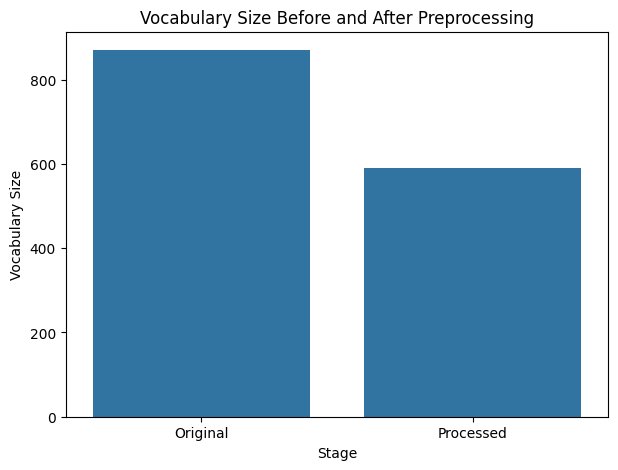

In [76]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=vocab_comparison,
    x="Stage",
    y="Vocabulary Size"
)

plt.title("Vocabulary Size Before and After Preprocessing")
plt.show()

In [77]:
output_path = "/content/sample_data/cleaned_support_tickets.csv"

df.to_csv(output_path, index=False)